Problem 1)

a)

In [ ]:

import numpy as np
from hmmlearn import hmm

#Initial probabilities (uniformly distribuited)
pi = np.array([0.25,0.25,0.25,0.25]) # Room's 1, 2, 3, 4


             # 1    2   3   4
A = np.array([[0.2,0.4,0.0,0.4], #From 1
              [0.4,0.2,0.4,0.0], # From 2 
              [0.0,0.4,0.2,0.4], #From 3
              [0.4,0.0,0.4,0.2]]) #From 4
                                


B  = np.array([[0.7, 0.2, 0.1],         # 1: red green blue
               [0.2, 0.6, 0.2],       # 2: red green blue 
               [0.1, 0.3, 0.6],       # 3: red green blue 
               [0.5, 0.2, 0.3]])       # 4: red green blue
                                                  
                                       

#CategoricalHMM:
model = hmm.CategoricalHMM(n_components=4, init_params="", params="")   
model.n_features = 3                    # number of observation symbols
model.startprob_ = pi
model.transmat_ = A
model.emissionprob_ = B

# red = 0, green = 1, blue = 2
o = [0,1,2,2,0]
X = np.array(o).reshape(-1, 1)  
states = ["1", "2", "3", "4"]


#Viterbi 

log_p, best_path = model.decode(X, algorithm="viterbi")
print("Most likely hidden states:", [states[s] for s in best_path])

def joint_prob(path, obs):
    p = pi[path[0]] * B[path[0], obs[0]]
    for t in range(1, len(obs)):
        p *= A[path[t-1], path[t]] * B[path[t], obs[t]]
    return p

print("Join probability =", f"{joint_prob(best_path, o):.4e}")




Most likely hidden states: ['1', '2', '3', '4', '1']
Join probability = 3.3869e-04


B)


In [27]:
             # 1    2   3   4
A = np.array([[0.0,0.5,0.0,0.5], #From 1
              [0.5,0.0,0.5,0.0], # From 2 
              [0.0,0.5,0.0,0.5], #From 3
              [0.5,0.0,0.5,0.0]]) #From 4
                                

                                                  
                    
#CategoricalHMM:
model = hmm.CategoricalHMM(n_components=4, init_params="", params="")   
model.n_features = 3                    # number of observation symbols
model.startprob_ = pi
model.transmat_ = A
model.emissionprob_ = B

# red = 0, green = 1, blue = 2
o = [0,1,2,2,0]
X = np.array(o).reshape(-1, 1)  
states = ["1", "2", "3", "4"]

#Viterbi 

log_p, best_path = model.decode(X, algorithm="viterbi")
print("Most likely hidden states:", [states[s] for s in best_path])

def joint_prob(path, obs):
    p = pi[path[0]] * B[path[0], obs[0]]
    for t in range(1, len(obs)):
        p *= A[path[t-1], path[t]] * B[path[t], obs[t]]
    return p

print("Join probability =", f"{joint_prob(best_path, o):.4e}")




Most likely hidden states: ['1', '2', '3', '4', '1']
Join probability = 8.2687e-04


The modified A has no self-loops and splits probability 0.5/0.5 between neighbouring rooms. The path never stays in a room, so it benefits.

Problem 3)

a)

The Beta prior is conjugate to the Binomial likelihood, so the posterior is Beta(2+5, 8+15) = Beta(7, 23). 

Posterior: Beta(7, 23)
Posterior mean = 0.233


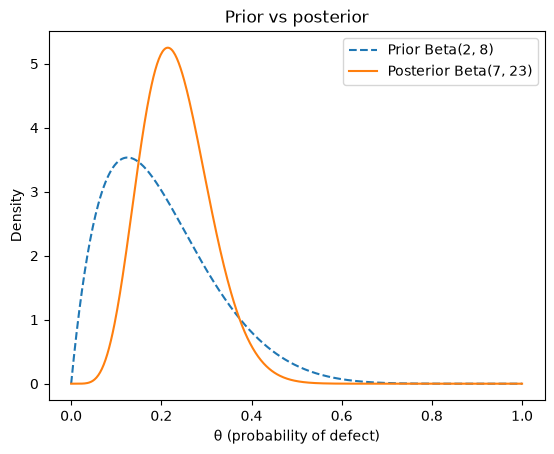

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

a0, b0 = 2, 8          
n, k = 20, 5          
a1, b1 = a0 + k, b0 + n - k   

print(f"Posterior: Beta({a1}, {b1})")
print(f"Posterior mean = {a1/(a1+b1):.3f}")

theta = np.linspace(0, 1, 500)
plt.plot(theta, stats.beta.pdf(theta, a0, b0), "--", label="Prior Beta(2, 8)")
plt.plot(theta, stats.beta.pdf(theta, a1, b1), label="Posterior Beta(7, 23)")
plt.xlabel("θ (probability of defect)"); plt.ylabel("Density")
plt.title("Prior vs posterior"); plt.legend()
plt.show()

B)


Posterior after both batches: Beta(10, 35)


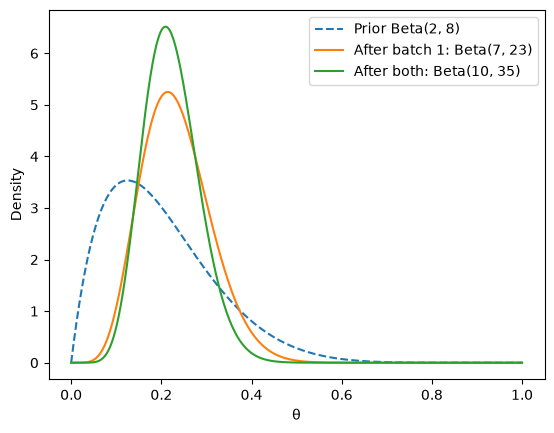

In [21]:
k2, n2 = 3, 15
a2, b2 = a1 + k2, b1 + n2 - k2     
print(f"Posterior after both batches: Beta({a2}, {b2})")

plt.plot(theta, stats.beta.pdf(theta, a0, b0), "--", label="Prior Beta(2, 8)")
plt.plot(theta, stats.beta.pdf(theta, a1, b1), label="After batch 1: Beta(7, 23)")
plt.plot(theta, stats.beta.pdf(theta, a2, b2), label="After both: Beta(10, 35)")
plt.xlabel("θ"); plt.ylabel("Density"); plt.legend()
plt.show()

C)


b) both batches: Beta(10,35) mean = 0.222222
c) batch 2 only: Beta(5,20) mean = 0.200000


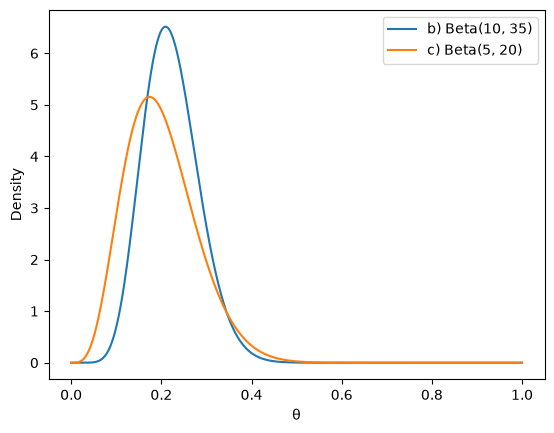

In [26]:
a3, b3 = a0 + k2, b0 + n2 - k2
for name, a, b in [("b) both batches", a2, b2), ("c) batch 2 only", a3, b3)]:
        print(f"{name}: Beta({a},{b}) mean = {a/(a+b):3f}")

plt.plot(theta, stats.beta.pdf(theta, a2, b2), label="b) Beta(10, 35)")
plt.plot(theta, stats.beta.pdf(theta, a3, b3), label="c) Beta(5, 20)")
plt.xlabel("θ"); plt.ylabel("Density"); plt.legend(); plt.show()

In b) the posterior Beta(10,35) uses all the information (prior + 35 products, 8 defective), while in c) Beta(5,20) ignores the first batch and uses only 15 products.
Therefore b) has a higher mean (0.222 vs 0.200), and its narrower, because more data means less uncertainty about theta. So c) is less precise

Problem 2)


A)

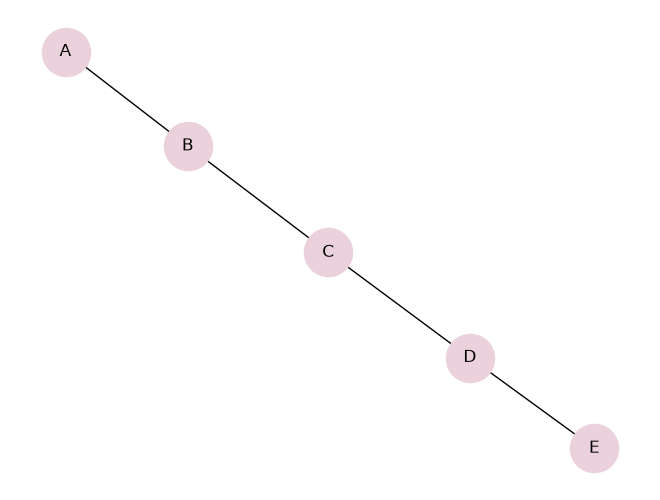

In [24]:
import networkx as nx

edges = [("A", "B"), ("B", "C"), ("C", "D"), ("D", "E")]
G = nx.Graph(edges)
nx.draw(G, with_labels=True, node_size=1200, node_color="#ead1dc", pos=nx.spring_layout(G, seed=1))
plt.show()

B)


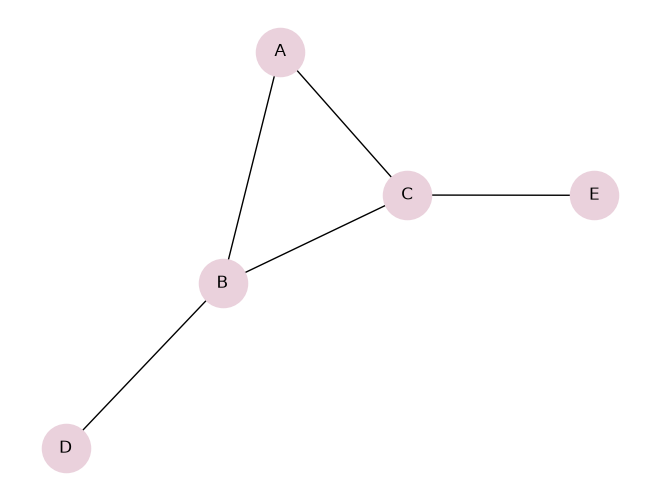

In [25]:
edges = [("A", "B"), ("A", "C"), ("B", "C"), ("B", "D"), ("C", "E")]
G = nx.Graph(edges)
nx.draw(G, with_labels=True, node_size=1200, node_color="#ead1dc", pos=nx.spring_layout(G, seed=1))
plt.show()